# Bibliotecas

In [35]:
import numpy as np
import pandas as pd
%load_ext autoreload
%autoreload 2
# from google.colab import drive
import os
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from tqdm.notebook import tqdm
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import confusion_matrix


import torch
import torch.nn as nn
import torch.optim as optim
from torchsummary import summary

In [2]:
sns.set_theme()

In [3]:
RANDOM_SEED = 33
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Selecionar dispositivo disponível
REQUESTED_DEVICE = "auto"

if REQUESTED_DEVICE == "auto":
  if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
  else:
    DEVICE = torch.device("cpu")
elif REQUESTED_DEVICE == "cuda":
  if not torch.cuda.is_available():
    raise RuntimeError("CUDA was requested, but no CUDA device is available.")
  DEVICE = torch.device("cuda")
else:
  raise ValueError("REQUESTED_DEVICE must be 'auto', 'cpu', 'cuda'.")

print(f"Using device: {DEVICE}")

Using device: cuda


# Download CIC IDS 2017

[Este](https://www.unb.ca/cic/datasets/ids-2017.html) conjunto de dados contém informações sobre fluxos de rede, representando tanto o tráfego benigno quanto ataques populares. Para o ambiente de teste desta coleta de dados, uma rede foi configurada para o atacante e uma rede separada foi configurada para as vítimas, esta última contendo firewalls, roteadores, switches, servidores e estações de trabalho em execução em diferentes versões dos sistemas operacionais Windows e Linux. Para gerar o tráfego benigno, os autores utilizaram um sistema desenvolvido por eles mesmos, que então extraiu o comportamento abstrato de 25 usuários com base em diferentes protocolos de aplicação. Os dados foram coletados ao longo de cinco dias de atividade de rede e foram processados para extrair mais de 80 features do conjunto de dados usando a ferramenta CICFlowMeter8.


In [ ]:
# update gdown version
!pip install --upgrade --no-cache-dir gdown

In [ ]:
# Download do Dataset
!gdown '1X9s72a_9VzukVbFhGKHW1xLnyrnqu3MP' -O CIC_IDS_2017.zip

In [ ]:
# Descompactando a pasta
!unzip ./CIC_IDS_2017.zip

# Carregando os dados

In [4]:
df_list = []
for file in os.listdir('data/CIC_IDS_2017/'):
  df_aux = pd.read_csv(f'data/CIC_IDS_2017/{file}')
  df_list.append(df_aux)
df = pd.concat(df_list, ignore_index=True)

Algumas colunas tem seus nomes iniciados com espaços ou finalizados com espaços. Vamos remover esses espaços não úteis para ajustar o nome das colunas.

In [5]:
df.columns = df.columns.str.strip()

# Limpando os dados

É necessário limpar os dados realizando:
- Descarte de registros duplicados
- Descarte de registros com valores NaN (Not a Number)/ Null / NA (Not Available)
- Evitar registros com valores não finitos. Nesse caso, uma abordagem válida é substituirmos os mesmos pelo maior valor finito presente no dataset.

Registros duplicados

In [6]:
# Descartando duplicadas
initial_len = df.shape[0]
df = df.drop_duplicates()
print(f'Tamanho inicial: {initial_len}, tamanho final {df.shape[0]} | Descartadas {initial_len - df.shape[0]} duplicadas')

Tamanho inicial: 2830743, tamanho final 2522362 | Descartadas 308381 duplicadas


Registros com valores Null/NaN/NA

In [7]:
# Descartando registros com valores NaN/Null/NA
initial_len = df.shape[0]
df = df.dropna()
print(f'Tamanho inicial: {initial_len}, tamanho final {df.shape[0]} | Descartados {initial_len - df.shape[0]} registros com valores NA')

Tamanho inicial: 2522362, tamanho final 2522009 | Descartados 353 registros com valores NA


In [8]:
df = df.reset_index(drop=True)

Registros com valores não finitos

In [9]:
# Evitando registros com valores não finitos
max_finite_flow_packets_per_sec = df[np.isfinite(df['Flow Packets/s'])]['Flow Packets/s'].max()
max_finite_flow_bytes_per_sec = df[np.isfinite(df['Flow Bytes/s'])]['Flow Bytes/s'].max()

df.loc[df['Flow Packets/s'] == np.inf, 'Flow Packets/s'] = max_finite_flow_packets_per_sec
df.loc[df['Flow Bytes/s'] == np.inf, 'Flow Bytes/s'] = max_finite_flow_bytes_per_sec

# Dividindo dados nos conjuntos de treino, validação e teste

**Conjunto de treino**

Para a detecção de anomalias, vamos usar somente os dados que representam o tráfego benigno para o conjunto de treino. Dessa forma, os algoritmos vão ser capazes de identificar padrões e desvios em relação ao comportamento normal (benigno) dos dados.

**Conjuntos de validação e teste**

Porém, devem ser incluídos dados que representam o tráfego maliciosos nos conjuntos de validação e teste. Esses dados maliciosos no conjunto de validação são importantes para que possamos definir um *threshold* para que seja possível detectar anomalias. Além disso, os dados maliciosos também precisam ser incluídos no conjunto de teste para que possamos avaliar o desempenho do nosso modelo.

In [10]:
df_train = df.query('Label == "BENIGN"').sample(frac=0.6, random_state=RANDOM_SEED)
df_val_test = df.drop(df_train.index)

df_train = df_train.reset_index(drop=True)
df_val_test = df_val_test.reset_index(drop=True)

X_train = df_train.drop('Label', axis='columns')

In [11]:
X_val, X_test, classes_val, classes_test = train_test_split(df_val_test.drop('Label', axis='columns'), df_val_test['Label'], test_size=0.65, stratify=df_val_test['Label'], random_state=RANDOM_SEED)

X_val, X_test = X_val.reset_index(drop=True), X_test.reset_index(drop=True)
classes_val, classes_test =  classes_val.reset_index(drop=True), classes_test.reset_index(drop=True)

y_val, y_test = classes_val.apply(lambda c: 0 if c == 'BENIGN' else 1), classes_test.apply(lambda c: 0 if c == 'BENIGN' else 1)

In [12]:
del df_train, df_val_test

# Analisando correlação entre features

**Por que remover features?**

Vamos descartar features com alta correlação evitando passar informações redundantes ao modelo. Dessa forma, conseguiremos obter um modelo mais simples e com menor custo computacional.

In [13]:
def get_highly_correlated_features(correlation_matrix, threshold):
  correlated_pairs = []
  for i in range(len(correlation_matrix.columns)):
    for j in range(i):
      if abs(correlation_matrix.iloc[i, j]) > threshold:
        pair = (correlation_matrix.columns[i], correlation_matrix.columns[j])
        coefficient = correlation_matrix.iloc[i, j]
        correlated_pairs.append((pair, coefficient))
  return sorted(correlated_pairs, key= lambda pair: pair[1], reverse=True)


In [14]:
corr_matrix = X_train.corr().abs()
correlation_list = get_highly_correlated_features(corr_matrix, 0.95)

In [15]:
correlation_list[:10]

[(('SYN Flag Count', 'Fwd PSH Flags'), np.float64(1.0)),
 (('CWE Flag Count', 'Fwd URG Flags'), np.float64(1.0)),
 (('Avg Fwd Segment Size', 'Fwd Packet Length Mean'), np.float64(1.0)),
 (('Avg Bwd Segment Size', 'Bwd Packet Length Mean'), np.float64(1.0)),
 (('Fwd Header Length.1', 'Fwd Header Length'), np.float64(1.0)),
 (('Subflow Fwd Packets', 'Total Fwd Packets'), np.float64(1.0)),
 (('Subflow Fwd Bytes', 'Total Length of Fwd Packets'), np.float64(1.0)),
 (('Subflow Bwd Packets', 'Total Backward Packets'), np.float64(1.0)),
 (('Subflow Bwd Bytes', 'Total Length of Bwd Packets'),
  np.float64(0.9999998619402976)),
 (('Subflow Fwd Packets', 'Total Backward Packets'),
  np.float64(0.9991954734499192))]

In [16]:
# Drop high correlated features in correlation list

f2drop = []
for feature_pair, _ in correlation_list:
  if feature_pair[0] not in f2drop and feature_pair[1] not in f2drop:
    f2drop.append(feature_pair[1])

In [17]:
f2drop

['Fwd PSH Flags',
 'Fwd URG Flags',
 'Fwd Packet Length Mean',
 'Bwd Packet Length Mean',
 'Fwd Header Length',
 'Total Fwd Packets',
 'Total Length of Fwd Packets',
 'Total Backward Packets',
 'Total Length of Bwd Packets',
 'Subflow Fwd Packets',
 'Flow Duration',
 'RST Flag Count',
 'Subflow Bwd Packets',
 'Packet Length Mean',
 'Flow IAT Max',
 'Idle Mean',
 'Fwd IAT Total',
 'Fwd Packet Length Max',
 'Max Packet Length',
 'Bwd IAT Max',
 'Bwd IAT Mean',
 'Fwd IAT Max',
 'Fwd IAT Mean',
 'Idle Max']

A feature "Destination Port", também não fornece muita contribuição devido que a mesma está codificada com valores inteiros, indicando uma relação de grandeza, como 44720 > 80, que não apresenta sentido semântico quando se trata da porta de destino de um fluxo de rede.

In [18]:
f2drop = f2drop + ['Destination Port']

In [19]:
X_train = X_train.drop(f2drop, axis='columns')
X_val = X_val.drop(f2drop, axis='columns')
X_test = X_test.drop(f2drop, axis='columns')

# Normalizando os dados

É importante normalizar os dados para lidar com diferentes escalas, sensibilidades a escalas e até mesmo melhorar o desempenho da convergência dos algoritmos.

Caso não seja realizada a normalização, um valor de 10000 para uma feature como "Flow Bytes/s" terá impacto similar ao modelo quanto um valor de 10000 para uma feature como "Flow Packets/s". Isso é prejudicial, pois o impacto desse valor para as duas features deve ser tratado de forma distinta, já que as mesmas têm escalas e sensibilidades também distintas.

In [20]:
std_scaler = MinMaxScaler()
std_scaler = std_scaler.fit(X_train)

norm_X_train = std_scaler.transform(X_train)
norm_X_val = std_scaler.transform(X_val)
norm_X_test = std_scaler.transform(X_test)

In [21]:
del X_train, X_val, X_test

# Detecção de Anomalias com Autoencoders

## Autoencoder - Explicação

<div align="center">

![Autoencoder](https://tikz.net/janosh/autoencoder.png)
</div>

Um autoencoder é uma arquitetura de rede neural que aprende a codificar dados em uma representação compacta, chamada de espaço latente, e então reconstruir os dados a partir dessa representação. Ele consiste em duas partes principais: o encoder, que mapeia os dados de entrada para o espaço latente, e o decoder, que reconstrói os dados a partir dessa representação. A ideia central é forçar o modelo a aprender uma representação eficiente e informativa dos dados de entrada.

<div align="center">

![img_autoencoder](https://blog.keras.io/img/ae/autoencoder_schema.jpg)
</div>

Os autoencoders são frequentemente usados para tarefas de redução de dimensionalidade e denoising. No entanto, eles também são aplicáveis à detecção de anomalias. A lógica é que um autoencoder treinado em dados normais aprenderá a representação latente desses dados, e quando apresentado com dados anômalos que diferem significativamente dos dados normais, a reconstrução será prejudicada, levando a um erro de reconstrução maior.

No exemplo a seguir treinamos um autoencoder com imagens dos números 3 e 7 apenas e depois inserimos o número 6 ao conjunto de teste como sendo uma anomalia:

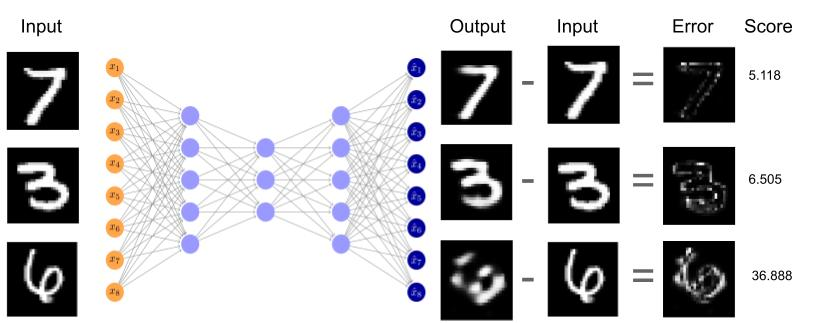

Como vemos, o autoencoder foi capaz de reconstruir as imágens do 3 e do 7 porém gerou uma imagem distorcida para o 6, o que leva a um maior erro de reconstrução e um maior score de anomalia, que nesse caso foi calculado como o erro quadrático entre a imagem de input e a de output.

## Relembrando o processo de treinamento de redes neurais - Backpropagation

<div align="center">

![Backpropagation](https://miro.medium.com/v2/resize:fit:640/format:webp/1*VF9xl3cZr2_qyoLfDJajZw.gif)
</div>

## Mecanismo de Early Stopping


<div align="center">

![Early stopping](https://www.researchgate.net/publication/356747729/figure/fig3/AS:1098404738408449@1638891505126/Early-stopping-training-is-stopped-as-soon-as-the-performance-on-the-validation-loss.jpg)
</div>

O mecanismo de Early Stopping é uma técnica usada durante o treinamento de redes neurais para evitar overfitting e melhorar a eficiência do modelo. O objetivo é interromper o treinamento assim que a performance do modelo em um conjunto de validação começa a piorar, em vez de continuar até que o desempenho no conjunto de treinamento seja perfeito.

O mesmo inclui usa dos seguintes argumentos para definir um critério de parada:
- **paciência**: Quantidade de épocas limite para esperar melhoria na loss de validação
- **delta**: Melhoria mínina necessária para atualizar uma loss de validação

In [22]:
# Implementação do Early Stopping
class EarlyStopping:
  def __init__(self, patience=7, delta=0, verbose=True, path='checkpoint.pt'):
      self.patience = patience
      self.delta = delta
      self.verbose = verbose
      self.counter = 0
      self.early_stop = False
      self.val_min_loss = np.inf
      self.path = path

  def __call__(self, val_loss, model):
    if val_loss < self.val_min_loss - self.delta:   # Caso a loss da validação reduza, vamos salvar o modelo e nova loss mínima
      self.save_checkpoint(val_loss, model)
      self.counter = 0
    else:                                           # Caso a loss da validação NÃO reduza, vamos incrementar o contador da paciencia
      self.counter += 1
      print(f'EarlyStopping counter: {self.counter} out of {self.patience}. Current validation loss: {val_loss:.5f}')
      if self.counter >= self.patience:
          self.early_stop = True

  def save_checkpoint(self, val_loss, model):
    if self.verbose:
        print(f'Validation loss decreased ({self.val_min_loss:.5f} --> {val_loss:.5f}).  Saving model ...')
    torch.save(model, self.path)
    self.val_min_loss = val_loss

## Autoencoder - Implementação

A estrutura básica do autoencoder que vamos montar é:

*features de entrada -> 24 -> 8 -> 24 -> features de entrada*

In [23]:
# Implementação do Autoencoder
class Autoencoder(nn.Module):
  def __init__(self, in_features, dropout_rate=0.2, device=None):
    super().__init__()

    self.in_features = in_features
    self.dropout_rate = dropout_rate
    self.early_stopping = None
    self.device = device if device is not None else DEVICE
    self.encoder = nn.Sequential(
      # Camada 1 de encoding:
      nn.Linear(in_features, 24),
      nn.BatchNorm1d(24),
      nn.ReLU(),
      nn.Dropout(dropout_rate),
      # Camada 2 de encoding:
      nn.Linear(24, 8),
      nn.BatchNorm1d(8),
      nn.ReLU()
    )

    self.decoder = nn.Sequential(
      # Camada 1 de decoding:
      nn.Linear(8, 24),
      nn.BatchNorm1d(24),
      nn.ReLU(),
      nn.Dropout(dropout_rate),
      # Camada 2 de decoding:
      nn.Linear(24, in_features),
      nn.BatchNorm1d(in_features),
      nn.Sigmoid()
    )
    self.to(self.device)

  def forward(self, X):
    X = X.to(self.device)
    encoded = self.encoder(X)
    decoded = self.decoder(encoded)
    return decoded

  def compile(self, learning_rate):
    self.criterion = nn.MSELoss()
    self.optimizer = optim.Adam(self.parameters(), lr = learning_rate)

  def fit(self, X_train, num_epochs, batch_size, X_val = None, patience = None, delta = None):
    if X_val is not None and patience is not None and delta is not None:
      print(f'Using early stopping with patience={patience} and delta={delta}')
      self.early_stopping = EarlyStopping(patience, delta)
    X_train = X_train.to(self.device)
    if X_val is not None:
      X_val = X_val.to(self.device)
    val_avg_losses = []
    train_avg_losses = []

    for epoch in range(num_epochs):
      # Calibrando os pesos do modelo
      train_losses = []
      self.train()
      for batch in tqdm(range(0, len(X_train), batch_size)):
        batch_X = X_train[batch:(batch+batch_size)]
        batch_reconstruction = self.forward(batch_X)

        train_loss = self.criterion(batch_reconstruction, batch_X)
        self.optimizer.zero_grad()
        train_loss.backward()
        self.optimizer.step()
        train_losses.append(train_loss.item())
      train_avg_loss = np.mean(train_losses)
      train_avg_losses.append(train_avg_loss)
      print(f'Epoch#{epoch+1}: Train Average Loss = {train_avg_loss:.5f}')

      # Mecanismo de early stopping
      if self.early_stopping is not None:
        val_losses = []
        self.eval()
        with torch.no_grad():
          for batch in range(0, len(X_val), batch_size):
            batch_X = X_val[batch:(batch+batch_size)]
            batch_reconstruction = self.forward(batch_X)
            val_loss = self.criterion(batch_reconstruction, batch_X)
            val_losses.append(val_loss.item())
        val_avg_loss = np.mean(val_losses)
        val_avg_losses.append(val_avg_loss)
        self.early_stopping(val_avg_loss, self)
        if self.early_stopping.early_stop:
          print(f'Stopped by early stopping at epoch {epoch+1}')
          break

    if self.early_stopping is not None:
      self = torch.load('checkpoint.pt', weights_only=False)
    self.eval()
    return train_avg_losses, val_avg_losses

In [31]:
BATCH_SIZE = 256
LR = 5e-3
PATIENCE = 2
DELTA = 0.001
NUM_EPOCHS = 3
IN_FEATURES = norm_X_train.shape[1]

In [32]:
ae_model = Autoencoder(IN_FEATURES, device=DEVICE)
ae_model.compile(learning_rate = LR)

In [ ]:
summary(ae_model, (IN_FEATURES,), device=str(DEVICE))

In [34]:
# Exemplo de treinamento sem utilizar Early Stopping

train_avg_losses, _ = ae_model.fit(torch.FloatTensor(norm_X_train), NUM_EPOCHS, BATCH_SIZE)

  0%|          | 0/4913 [00:00<?, ?it/s]

Epoch#1: Train Average Loss = 0.01528


  0%|          | 0/4913 [00:00<?, ?it/s]

Epoch#2: Train Average Loss = 0.00165


  0%|          | 0/4913 [00:00<?, ?it/s]

Epoch#3: Train Average Loss = 0.00134


In [35]:
# Exemplo de treinamento utilizando Early Stopping

# Passo 1: Considerar apenas amostras benignas no conjunto de validação
benign_norm_X_val = norm_X_val[y_val == 0]
benign_norm_X_val = torch.FloatTensor(benign_norm_X_val)

# Passo 2: Realizar treinamento do modelo
NUM_EPOCHS = 10
ae_model_with_es = Autoencoder(IN_FEATURES)
ae_model_with_es.compile(learning_rate = LR)
train_avg_losses, val_avg_losses = ae_model_with_es.fit(torch.FloatTensor(norm_X_train),
                                                NUM_EPOCHS,
                                                BATCH_SIZE,
                                                X_val = benign_norm_X_val,
                                                patience=PATIENCE,
                                                delta=DELTA)

Using early stopping with patience=2 and delta=0.001


  0%|          | 0/4913 [00:00<?, ?it/s]

Epoch#1: Train Average Loss = 0.01470
Validation loss decreased (inf --> 0.00146).  Saving model ...


  0%|          | 0/4913 [00:00<?, ?it/s]

Epoch#2: Train Average Loss = 0.00203
EarlyStopping counter: 1 out of 2. Current validation loss: 0.00077


  0%|          | 0/4913 [00:00<?, ?it/s]

Epoch#3: Train Average Loss = 0.00147
EarlyStopping counter: 2 out of 2. Current validation loss: 0.00070
Stopped by early stopping at epoch 3


Abaixo podemos ver um gráfico que exibe as losses (perdas) de treino e validação ao longo das épocas de treinamento. As losses são medidas que indicam quão bem o modelo está aprendendo a tarefa específica para a qual foi treinado. Esse gráfico nos possibilita:

- Acompanhar o treinamento
- Detectar overfitting
- Visualizar a convergência do modelo

In [29]:
def plot_train_val_losses(train_avg_losses, val_avg_losses):
  epochs = list(range(1, len(train_avg_losses)+1))
  plt.plot(epochs, train_avg_losses, color='blue', label='Loss do treino')
  plt.plot(epochs, val_avg_losses, color='orange', label='Loss da validação')
  plt.title('Losses de treino e validação por época de treinamento')
  plt.legend()


In [ ]:
plot_train_val_losses(train_avg_losses, val_avg_losses)

# Definindo um threshold e avaliando resultados

## Funções Auxiliares

In [24]:
def plot_roc_curve(y_true, y_score, max_fpr=1.0):
  fpr, tpr, thresholds = roc_curve(y_true, y_score)
  aucroc = roc_auc_score(y_true, y_score)
  plt.plot(100*fpr[fpr < max_fpr], 100*tpr[fpr < max_fpr], label=f'ROC Curve (AUC = {aucroc:.4f})')
  plt.xlim(-2,102)
  plt.xlabel('FPR (%)')
  plt.ylabel('TPR (%)')
  plt.legend()
  plt.title('ROC Curve and AUCROC')

In [25]:
def get_tpr_per_attack(y_labels, y_pred):
  aux_df = pd.DataFrame({'Label':y_labels,'prediction':y_pred})
  total_per_label = aux_df['Label'].value_counts().to_dict()
  correct_predictions_per_label = aux_df.query('Label != "BENIGN" and prediction == True').groupby('Label').size().to_dict()
  tpr_per_attack = {}
  for attack_label, total in total_per_label.items():
    if attack_label == 'BENIGN':
      continue
    tp = correct_predictions_per_label[attack_label] if attack_label in correct_predictions_per_label else 0
    tpr = tp/total
    tpr_per_attack[attack_label] = tpr
  return tpr_per_attack

In [26]:
def get_overall_metrics(y_true, y_pred):
  tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
  acc = (tp+tn)/(tp+tn+fp+fn)
  tpr = tp/(tp+fn)
  fpr = fp/(fp+tn)
  precision = tp/(tp+fp)
  f1 = (2*tpr*precision)/(tpr+precision)
  return {'acc':acc,'tpr':tpr,'fpr':fpr,'precision':precision,'f1-score':f1}

In [27]:
def plot_confusion_matrix(y_true, y_pred):
  cm = confusion_matrix(y_true, y_pred)
  group_counts = [f'{value:.0f}' for value in confusion_matrix(y_true, y_pred).ravel()]
  group_percentages = [f'{value*100:.2f}%' for value in confusion_matrix(y_true, y_pred).ravel()/np.sum(cm)]
  labels = [f'{v1}\n{v2}' for v1, v2 in zip(group_counts, group_percentages)]
  labels = np.array(labels).reshape(2,2)
  sns.heatmap(cm, annot=labels, cmap='Oranges', xticklabels=['Predicted Benign', 'Predicted Malicious'], yticklabels=['Actual Benign', 'Actual Malicious'], fmt='')
  return

In [28]:
def get_autoencoder_anomaly_scores(ae_model, X, device=DEVICE):

  X = torch.FloatTensor(X).to(device)
  reconstructed_X = ae_model(X)
  anomaly_scores = torch.mean(torch.pow(X - reconstructed_X, 2), axis=1).detach().cpu().numpy() # MSELoss
  return anomaly_scores

## Conjunto de validação

In [42]:
val_anomaly_scores = get_autoencoder_anomaly_scores(ae_model, norm_X_val, device=DEVICE)

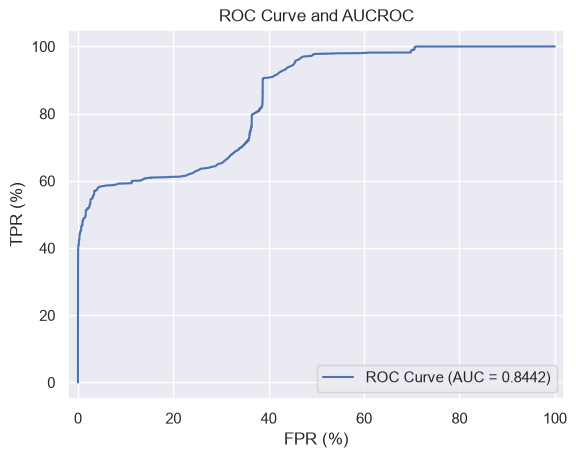

In [43]:
plot_roc_curve(y_val, val_anomaly_scores)

In [44]:
fpr, tpr, thresholds = roc_curve(y_val, val_anomaly_scores)
df_val_roc = pd.DataFrame({'fpr':fpr, 'tpr':tpr, 'thresholds':thresholds})
df_val_roc['youden-index'] = df_val_roc['tpr'] - df_val_roc['fpr']
df_val_roc.sort_values('youden-index', ascending=False).drop_duplicates('fpr').query('fpr < 0.03')

,fpr,tpr,thresholds,youden-index
6696,0.027609,0.546332,0.005016,0.518723
6698,0.027615,0.546338,0.005016,0.518723
6690,0.027592,0.546311,0.005018,0.518720
6692,0.027598,0.546318,0.005017,0.518720
6694,0.027605,0.546325,0.005017,0.518720
...,...,...,...,...
78,0.000014,0.088866,0.065171,0.088852
76,0.000010,0.088859,0.065174,0.088849
74,0.000007,0.088819,0.065179,0.088812
30,0.000003,0.044165,0.082576,0.044161


In [45]:
BEST_VALIDATION_THRESHOLD = 0.007941

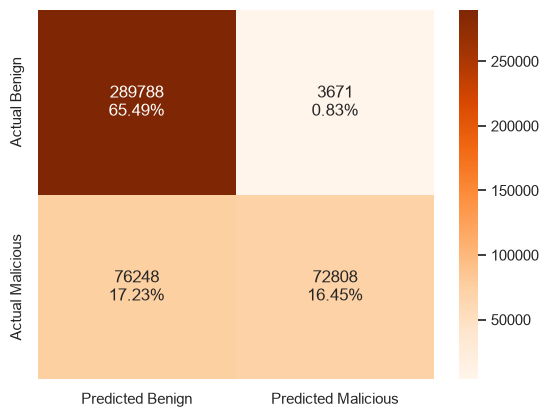

In [46]:
plot_confusion_matrix(y_val, val_anomaly_scores > BEST_VALIDATION_THRESHOLD)

In [47]:
get_overall_metrics(y_val, val_anomaly_scores > BEST_VALIDATION_THRESHOLD)

{'acc': np.float64(0.8193982124899721),
 'tpr': np.float64(0.48846071275225417),
 'fpr': np.float64(0.012509413580772783),
 'precision': np.float64(0.9519998953961218),
 'f1-score': np.float64(0.6456470170926908)}

In [48]:
get_tpr_per_attack(classes_val, val_anomaly_scores > BEST_VALIDATION_THRESHOLD)

{'DoS Hulk': 0.8364519968262365,
 'DDoS': 0.44141409632638484,
 'PortScan': 0.0070469059678484915,
 'DoS GoldenEye': 0.4191666666666667,
 'FTP-Patator': 0.0009633911368015414,
 'DoS slowloris': 0.23925729442970822,
 'DoS Slowhttptest': 0.11912568306010929,
 'SSH-Patator': 0.0008873114463176575,
 'Bot': 0.02342606149341142,
 'Web Attack � Brute Force': 0.0,
 'Web Attack � XSS': 0.0,
 'Infiltration': 0.23076923076923078,
 'Web Attack � Sql Injection': 0.0,
 'Heartbleed': 1.0}

## Conjunto de teste

In [49]:
test_anomaly_scores = get_autoencoder_anomaly_scores(ae_model, norm_X_test)

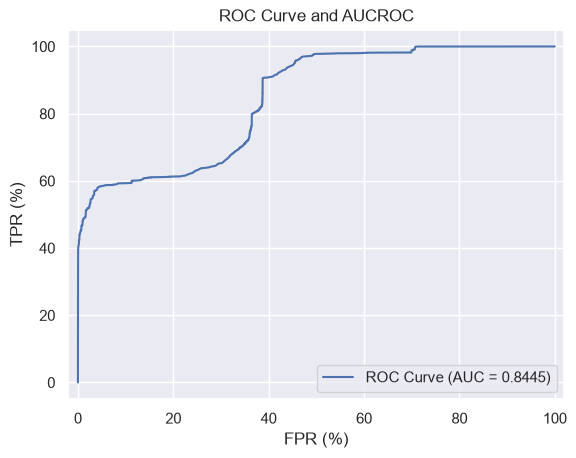

In [50]:
plot_roc_curve(y_test, test_anomaly_scores)

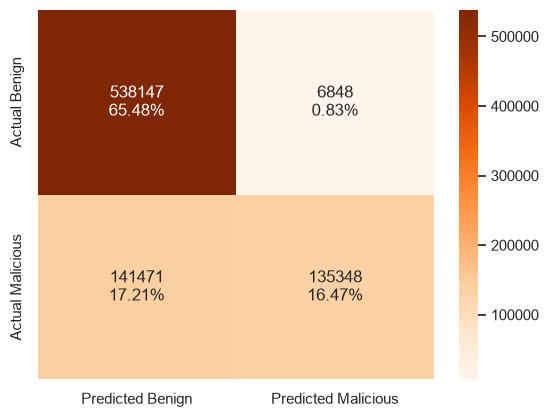

In [51]:
plot_confusion_matrix(y_test, test_anomaly_scores > BEST_VALIDATION_THRESHOLD)

In [52]:
get_overall_metrics(y_test, test_anomaly_scores > BEST_VALIDATION_THRESHOLD)

{'acc': np.float64(0.8195224223486093),
 'tpr': np.float64(0.48894042677706373),
 'fpr': np.float64(0.012565252892228368),
 'precision': np.float64(0.9518411207066303),
 'f1-score': np.float64(0.6460293784232068)}

In [53]:
get_tpr_per_attack(classes_test, test_anomaly_scores > BEST_VALIDATION_THRESHOLD)

{'DoS Hulk': 0.8342056074766355,
 'DDoS': 0.4457997836798462,
 'PortScan': 0.007402764602249627,
 'DoS GoldenEye': 0.41938378701764883,
 'FTP-Patator': 0.0005185377236193933,
 'DoS slowloris': 0.23742857142857143,
 'DoS Slowhttptest': 0.12065921130076515,
 'SSH-Patator': 0.0,
 'Bot': 0.025984251968503937,
 'Web Attack � Brute Force': 0.0,
 'Web Attack � XSS': 0.0,
 'Infiltration': 0.2608695652173913,
 'Web Attack � Sql Injection': 0.0,
 'Heartbleed': 1.0}

# Atividade de código

Autoencoders podem ter diferentes arquiteturas de redes neurais para funcionar. O autoencoder visto acima possui as seguintes camadas (representadas juntamente com suas respectivas quantidades de neurônios):

*features de entrada -> 24 neurônios -> 8 neurônios -> 24 neurônios -> features de entrada *

**Crie você mesmo e avalie resultados de um autoencoder com uma nova arquitetura, faça alterações na arquitetura visando melhorar a capacidade de detecção da rede**


In [ ]:
class NewAutoencoder(nn.Module):
  def __init__(self, in_features, dropout_rate=0.2, device=None):
    super().__init__()

    self.in_features = in_features
    self.dropout_rate = dropout_rate
    self.early_stopping = None
    self.device = device if device is not None else DEVICE
    self.encoder = nn.Sequential(
      # Camada 1 de encoding:
      nn.Linear(in_features, 72),
      nn.BatchNorm1d(72),
      nn.ReLU(),
      nn.Dropout(dropout_rate),

      # Camada 2 de encoding:
      nn.Linear(72, 56),
      nn.BatchNorm1d(56),
      nn.ReLU(),
      nn.Dropout(dropout_rate),
      
      # Camada 3 de encoding:
      nn.Linear(56, 40),
      nn.BatchNorm1d(40),
      nn.ReLU(),
      nn.Dropout(dropout_rate),

      # Camada 4 de encoding:
      nn.Linear(40, 24),
      nn.BatchNorm1d(24),
      nn.ReLU(),
      nn.Dropout(dropout_rate),

      # Camada 5 de encoding:
      nn.Linear(24, 8),
      nn.BatchNorm1d(8),
      nn.ReLU()
    )

    self.decoder = nn.Sequential(
      
      # Camada 1 de decoding:
      nn.Linear(8, 24),
      nn.BatchNorm1d(24),
      nn.ReLU(),
      nn.Dropout(dropout_rate),

      # Camada 3 de decoding:
      nn.Linear(24, 40),
      nn.BatchNorm1d(40),
      nn.ReLU(),
      nn.Dropout(dropout_rate),

      # Camada 4 de decoding:
      nn.Linear(40, 56),
      nn.BatchNorm1d(56),
      nn.ReLU(),
      nn.Dropout(dropout_rate),

      # Camada 5 de decoding:
      nn.Linear(56, 72),
      nn.BatchNorm1d(72),
      nn.ReLU(),
      nn.Dropout(dropout_rate),

      nn.Linear(72, in_features),
      nn.BatchNorm1d(in_features),
      nn.Sigmoid()
    )
    self.to(self.device)

  
  def forward(self, X):
    X = X.to(self.device)
    encoded = self.encoder(X)
    decoded = self.decoder(encoded)
    return decoded

  def compile(self, learning_rate):
    self.criterion = nn.MSELoss()
    self.optimizer = optim.Adam(self.parameters(), lr = learning_rate)

  def fit(self, X_train, num_epochs, batch_size, X_val = None, patience = None, delta = None):
    if X_val is not None and patience is not None and delta is not None:
      print(f'Using early stopping with patience={patience} and delta={delta}')
      self.early_stopping = EarlyStopping(patience, delta, path='autoencoder_checkpoint.pt')

    X_train = X_train.to(self.device)
    if X_val is not None:
      X_val = X_val.to(self.device)
      
    val_avg_losses = []
    train_avg_losses = []

    for epoch in range(num_epochs):
      # Calibrando os pesos do modelo
      train_losses = []
      self.train()
      for batch in tqdm(range(0, len(X_train), batch_size)):
        batch_X = X_train[batch:(batch+batch_size)]
        batch_reconstruction = self.forward(batch_X)

        train_loss = self.criterion(batch_reconstruction, batch_X)
        self.optimizer.zero_grad()
        train_loss.backward()
        self.optimizer.step()
        train_losses.append(train_loss.item())
      train_avg_loss = np.mean(train_losses)
      train_avg_losses.append(train_avg_loss)
      print(f'Epoch#{epoch+1}: Train Average Loss = {train_avg_loss:.5f}')

      # Mecanismo de early stopping
      if self.early_stopping is not None:
        val_losses = []
        self.eval()
        with torch.no_grad():
          for batch in range(0, len(X_val), batch_size):
            batch_X = X_val[batch:(batch+batch_size)]
            batch_reconstruction = self.forward(batch_X)
            val_loss = self.criterion(batch_reconstruction, batch_X)
            val_losses.append(val_loss.item())
        val_avg_loss = np.mean(val_losses)
        val_avg_losses.append(val_avg_loss)
        self.early_stopping(val_avg_loss, self)
        if self.early_stopping.early_stop:
          print(f'Stopped by early stopping at epoch {epoch+1}')
          break

    if self.early_stopping is not None:
      self = torch.load('autoencoder_checkpoint.pt', weights_only=False)
    self.eval()
    return train_avg_losses, val_avg_losses


Relembrando divisão dos dados

treino: 60% benigno

validação: 14% benigno + 35% malicioso

teste: 26% benigno + 65% malicioso

#### Testes

Todos baseados na arquitetura pré-determinada :
- batch_size = 128
- lr = 5e-3
- delta = 1e-3
- num_epochs = 10
- dropout_rate = 0.2

Batch normalization e Dropout em todas as camadas exceto na última de ambos encoder e decoder

Métricas de resultados obtidas dos conjuntos de validação 




1. Enc/Dec -> (128, 128) / (128, 128) 
2. Enc/Dec -> (48,24,8) / (24, 48)
3. Enc/Dec -> (48, 24, 8) e (8, 24, 48)
    - Resultados:
        1. F1: 0.6977846026286958
    - Decisão: manter simetria de layers e neurônios para ambos enc/dec

4. Enc/Dec -> (72, 48, 16) / (16, 48, 72)
    - Resultados:
        1. F1: 0.700776253076613
5. Enc/Dec -> (256, 256, 256, 128) / (128, 256, 256, 256)
    - lr=1e-3
    - batch_size = 64
    - Resultados:
        - F1: 0.68489

6. Enc/Dec -> (72, 48, 16) / (16, 48, 72)
    - lr = 2.5e-3
    - delta = 1e-4
    - batch_size = 64
    - num_epochs = 15
    - patience = 3 
    - Resultados:
        1. AUCROC: 0.834603
        2. F1: 0.727550

7. Enc/Dec -> (72, 56, 40, 24, 8) / (8, 24, 40, 56, 72)
    - lr = 2.5e-3
    - delta = 1e-4
    - batch_size = 64
    - Resultados:
        1. AUCROC: 0.8736
        2. F1: 0.6981839

8. Enc/Dec -> (72, 56, 40, 24, 8) / (8, 24, 40, 56, 72)
    - lr = 2e-3
    - delta = 1e-4
    - batch_size = 64
    - Resultados: 
        1. AUCROC: 0.874277
        2. F1: 0.706731

9. Enc/Dec -> (72, 56, 40, 24, 8) / (8, 24, 40, 56, 72)
    - lr = 2e-3
    - delta = 1e-4
    - dropout_rate = 0.25
    - batch_size = 64
    - num_epochs = 15
    - patience = 3
    - Resultados:
        1. AUCROC: 0.882268
        2. F1: 0.699125
    

In [258]:
BATCH_SIZE = 64
LR = 2e-3
PATIENCE = 3
DELTA = 0.0001
NUM_EPOCHS = 15
DROPOUT_RATE = 0.2
IN_FEATURES = norm_X_train.shape[1]

In [259]:
new_ae_model = NewAutoencoder(IN_FEATURES, dropout_rate=DROPOUT_RATE)
new_ae_model.compile(learning_rate=LR)
summary(new_ae_model, (IN_FEATURES,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                   [-1, 72]           3,888
       BatchNorm1d-2                   [-1, 72]             144
              ReLU-3                   [-1, 72]               0
           Dropout-4                   [-1, 72]               0
            Linear-5                   [-1, 56]           4,088
       BatchNorm1d-6                   [-1, 56]             112
              ReLU-7                   [-1, 56]               0
           Dropout-8                   [-1, 56]               0
            Linear-9                   [-1, 40]           2,280
      BatchNorm1d-10                   [-1, 40]              80
             ReLU-11                   [-1, 40]               0
          Dropout-12                   [-1, 40]               0
           Linear-13                   [-1, 24]             984
      BatchNorm1d-14                   

In [260]:
train_losses, val_losses = new_ae_model.fit(torch.FloatTensor(norm_X_train), NUM_EPOCHS, BATCH_SIZE, torch.FloatTensor(norm_X_val), PATIENCE, DELTA)

Using early stopping with patience=3 and delta=0.0001


  0%|          | 0/19652 [00:00<?, ?it/s]

Epoch#1: Train Average Loss = 0.01054
Validation loss decreased (inf --> 0.00873).  Saving model ...


  0%|          | 0/19652 [00:00<?, ?it/s]

Epoch#2: Train Average Loss = 0.00205
Validation loss decreased (0.00873 --> 0.00845).  Saving model ...


...

Epoch#7: Train Average Loss = 0.00157
EarlyStopping counter: 1 out of 3. Current validation loss: 0.00817


  0%|          | 0/19652 [00:00<?, ?it/s]

Epoch#8: Train Average Loss = 0.00154
EarlyStopping counter: 2 out of 3. Current validation loss: 0.00843


  0%|          | 0/19652 [00:00<?, ?it/s]

Epoch#9: Train Average Loss = 0.00152
EarlyStopping counter: 3 out of 3. Current validation loss: 0.00838
Stopped by early stopping at epoch 9


In [261]:
val_anomaly_scores = get_autoencoder_anomaly_scores(new_ae_model, norm_X_val)

In [262]:
fpr, tpr, thresholds = roc_curve(y_val, val_anomaly_scores)
df_val_roc = pd.DataFrame({'fpr':fpr, 'tpr':tpr, 'thresholds':thresholds})
df_val_roc['youden-index'] = df_val_roc['tpr'] - df_val_roc['fpr']
df_val_roc_sorted = df_val_roc.sort_values('youden-index', ascending=False).drop_duplicates('fpr').query('fpr < 0.03')

In [263]:
# BEST_NEW_VALIDATION_THRESHOLD = 0.015326
BEST_NEW_VALIDATION_THRESHOLD = df_val_roc_sorted.iloc[0]['thresholds']
print(f'Best new validation threshold: {BEST_NEW_VALIDATION_THRESHOLD:.6f}')
aucroc = roc_auc_score(y_val, val_anomaly_scores)
print(f'AUC-ROC: {aucroc:.6f}')

Best new validation threshold: 0.009008
AUC-ROC: 0.875939


In [264]:
get_overall_metrics(y_val, val_anomaly_scores > BEST_NEW_VALIDATION_THRESHOLD)

{'acc': np.float64(0.8419850174570354),
 'tpr': np.float64(0.5883963074280807),
 'fpr': np.float64(0.029210213351779975),
 'precision': np.float64(0.9109643109393826),
 'f1-score': np.float64(0.7149821466421014)}

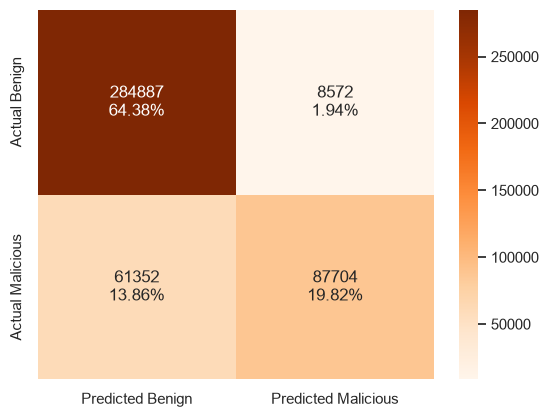

In [265]:
plot_confusion_matrix(y_val, val_anomaly_scores > BEST_NEW_VALIDATION_THRESHOLD)

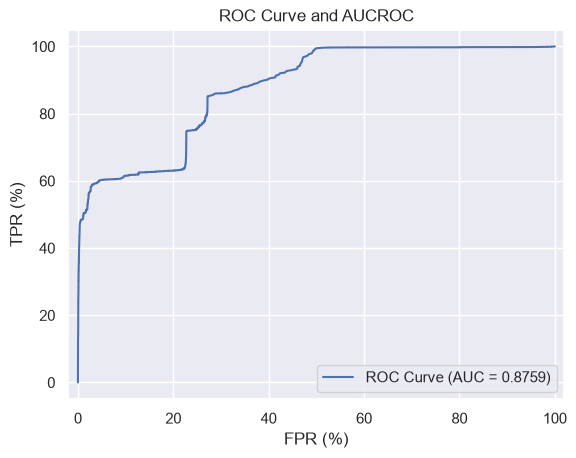

In [266]:
plot_roc_curve(y_val, val_anomaly_scores)

In [267]:
test_anomaly_scores = get_autoencoder_anomaly_scores(new_ae_model, norm_X_test)

In [268]:
get_overall_metrics(y_test, test_anomaly_scores > BEST_NEW_VALIDATION_THRESHOLD)

{'acc': np.float64(0.8416807209417216),
 'tpr': np.float64(0.5882905436404293),
 'fpr': np.float64(0.029614950595877026),
 'precision': np.float64(0.9098273646572435),
 'f1-score': np.float64(0.7145536836701337)}

In [269]:
get_tpr_per_attack(classes_test, test_anomaly_scores > BEST_NEW_VALIDATION_THRESHOLD)

{'DoS Hulk': 0.9345438362260792,
 'DDoS': 0.6230981853142651,
 'PortScan': 0.008063423228079685,
 'DoS GoldenEye': 0.594226742446904,
 'FTP-Patator': 0.0005185377236193933,
 'DoS slowloris': 0.24171428571428571,
 'DoS Slowhttptest': 0.19540906415538553,
 'SSH-Patator': 0.0,
 'Bot': 0.025196850393700787,
 'Web Attack � Brute Force': 0.0,
 'Web Attack � XSS': 0.0,
 'Infiltration': 0.2608695652173913,
 'Web Attack � Sql Injection': 0.0,
 'Heartbleed': 1.0}

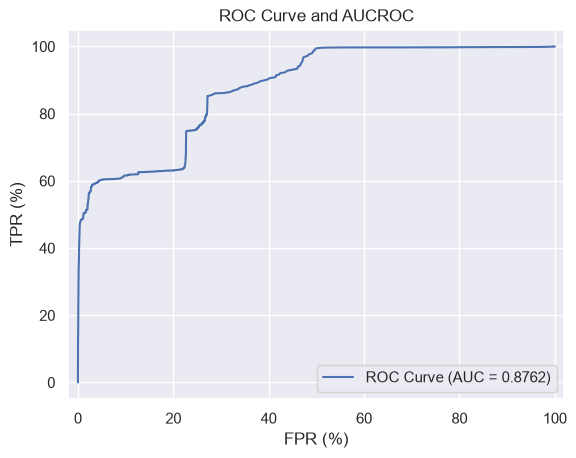

In [270]:
plot_roc_curve(y_test, test_anomaly_scores)

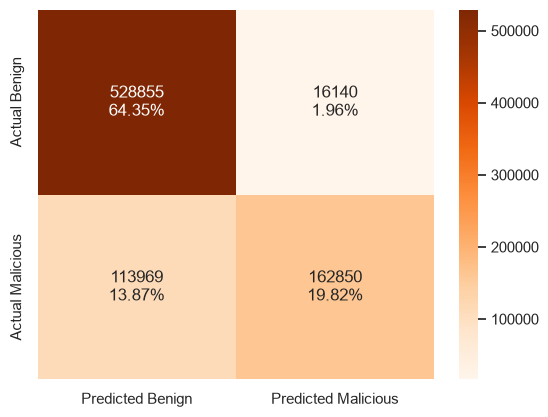

In [271]:
plot_confusion_matrix(y_test, test_anomaly_scores > BEST_NEW_VALIDATION_THRESHOLD)